# TP1 : descente de gradient à la main sur des contrats d'assurance auto

Objectif : refaire à la main ce que font `nn.Linear` et l'optimiseur de la démo 1. Un modèle linéaire prédit le coefficient de bonus-malus d'un contrat d'assurance auto à partir de trois informations : l'âge du conducteur, l'âge du véhicule et le nombre de sinistres. Vous observez d'abord ce qui se passe quand on oublie de remettre les gradients à zéro, puis vous corrigez la boucle.

L'énoncé complet, avec les critères de réussite, est dans `enonce.md`.

**Corrigé.** *Les sorties enregistrées dans ce notebook viennent d'une exécution dans Google Colab sur GPU A100, avec la graine fixée. Sur un autre GPU ou sur CPU, certaines valeurs peuvent légèrement différer : PyTorch ne garantit pas des résultats identiques d'une plateforme à l'autre.*

## Installation

Cette cellule écrit `requirements-colab.txt` (les versions de la formation, alignées sur le runtime Colab), puis l'installe avec uv. Les paquets déjà présents à la bonne version ne sont pas réinstallés. Hors de Colab, elle n'installe rien : l'environnement uv du projet contient déjà ces versions.

In [1]:
import importlib.util
from pathlib import Path

Path("requirements-colab.txt").write_text("""torch==2.11.0
torchvision==0.26.0
numpy==2.1.3
matplotlib==3.10.0
pillow==11.3.0
scikit-learn==1.6.1
pandas==2.2.2; python_version < "3.13"
pandas==2.2.3; python_version >= "3.13"
pyarrow>=14
tensorboard==2.21.0
onnx==1.23.0
onnxruntime==1.30.0
onnxscript==0.7.2
torchserve==0.12.0
torch-model-archiver==0.12.0
""")

if importlib.util.find_spec("google.colab") is not None:
    %pip install -q --progress-bar off uv
    !uv pip install --system -q -r requirements-colab.txt
else:
    print("Hors Colab : environnement uv du projet, rien à installer.")

Hors Colab : environnement uv du projet, rien à installer.


## Préparation (fournie)

**Données** : freMTPL2freq, contrats d'assurance responsabilité civile automobile en France (OpenML, licence CC0). Pour chaque contrat : âge du conducteur, âge du véhicule, nombre de sinistres, et le coefficient de bonus-malus à prédire (de 50 à 230 ; plus il est élevé, plus le conducteur est considéré comme risqué).

In [2]:
def charger_contrats(n=5000, seed=0):
    """Contrats d'assurance auto tirés au hasard, dans une table pandas aux colonnes renommées en français."""
    from sklearn.datasets import fetch_openml

    table = fetch_openml(data_id=41214, as_frame=True, parser="pandas").frame
    table = table.sample(n=n, random_state=seed).reset_index(drop=True)
    table = table.rename(columns={
        "Exposure": "exposition", "DrivAge": "age_conducteur", "VehAge": "age_vehicule",
        "VehPower": "puissance", "VehGas": "carburant", "Density": "densite", "Region": "region",
        "ClaimNb": "nb_sinistres", "BonusMalus": "bonus_malus",
    })
    table["carburant"] = table["carburant"].str.strip("'")
    colonnes = ["age_conducteur", "age_vehicule", "nb_sinistres", "exposition", "puissance", "carburant",
                "densite", "region", "bonus_malus"]
    return table[colonnes]

In [3]:
table = charger_contrats(n=5000)
table.head()

,age_conducteur,age_vehicule,nb_sinistres,exposition,puissance,carburant,densite,region,bonus_malus
0,55,18,0,1.00,7,Diesel,43,R24,50
1,40,16,0,0.08,4,Regular,1765,R31,55
2,72,13,0,1.00,4,Regular,49,R24,50
3,39,0,0,0.12,10,Regular,528,R93,50
4,57,10,0,0.23,7,Diesel,113,R91,50


## Étape 0 : découvrir les données (fournie)

Exécutez les cellules, puis répondez aux questions.

In [4]:
table[["age_conducteur", "age_vehicule", "nb_sinistres", "bonus_malus"]].describe().round(1)

,age_conducteur,age_vehicule,nb_sinistres,bonus_malus
count,5000.0,5000.0,5000.0,5000.0
mean,45.5,7.0,0.0,59.8
std,14.2,5.6,0.2,15.6
min,18.0,0.0,0.0,50.0
25%,34.0,2.0,0.0,50.0
50%,44.0,6.0,0.0,50.0
75%,55.0,11.0,0.0,64.0
max,96.0,50.0,3.0,196.0


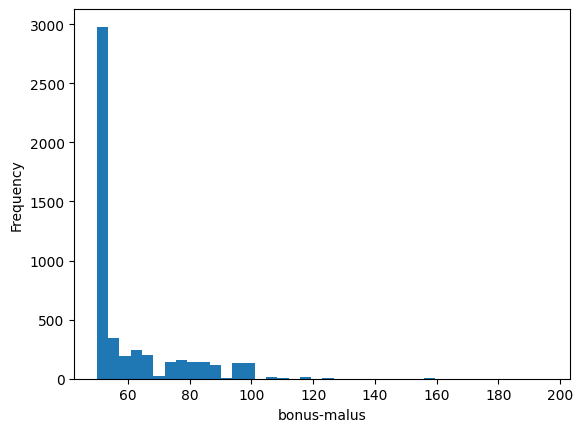

In [5]:
import matplotlib.pyplot as plt

table["bonus_malus"].plot(kind="hist", bins=40, xlabel="bonus-malus")
plt.show()

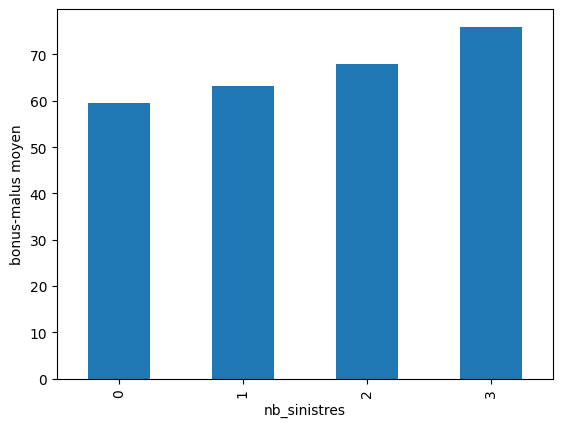

In [6]:
table.groupby("nb_sinistres")["bonus_malus"].mean().plot(kind="bar", ylabel="bonus-malus moyen")
plt.show()

Questions : quelle valeur de bonus-malus est la plus fréquente ? Le bonus-malus moyen augmente-t-il avec le nombre de sinistres ?

*Vos réponses :*

**Corrigé.** La valeur la plus fréquente est 50, le bonus maximal : c'est la médiane, et l'histogramme en montre un pic très haut. Le bonus-malus moyen augmente avec le nombre de sinistres, d'environ 60 sans sinistre à plus de 70 avec trois sinistres.

## Du tableau au tenseur (fourni)

Les trois informations deviennent un tenseur `x` de 5000 lignes et 3 colonnes, et la cible un tenseur `y`. Comme dans la démo 1, on remet les colonnes à la même échelle : chacune est centrée et réduite (moyenne 0, écart-type 1).

In [7]:
import torch

colonnes = ["age_conducteur", "age_vehicule", "nb_sinistres"]
features = torch.tensor(table[colonnes].to_numpy(dtype="float32"))
x = (features - features.mean(dim=0)) / features.std(dim=0)
y = torch.tensor(table["bonus_malus"].to_numpy(dtype="float32"))
print(x.shape, y.shape)

torch.Size([5000, 3]) torch.Size([5000])


## Étape 1 : le modèle et l'erreur

Le modèle linéaire : `x @ w + b`, un poids par colonne plus un biais. L'erreur : la moyenne des carrés des écarts. Chaque réponse tient en une ligne.

In [8]:
def model(x, w, b):
    return x @ w + b


def loss_fn(prediction, y):
    return ((prediction - y) ** 2).mean()

In [9]:
w = torch.zeros(3, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
assert model(x, w, b).shape == (5000,), "une prédiction par contrat"
print("erreur de départ :", loss_fn(model(x, w, b), y).item())

erreur de départ : 3817.653564453125


**Corrigé.** Avec `w` et `b` à zéro, le modèle prédit 0 pour tout le monde : l'erreur de départ, 3817.65, est énorme, puisque les bonus-malus valent au moins cinquante.

## Étape 2 : deux backward de suite

Ajoutez l'appel qui calcule les gradients. La boucle le fait deux fois, sans remise à zéro. Prédisez le second gradient avant d'exécuter.

In [10]:
w = torch.zeros(3, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
for appel in range(2):
    loss = loss_fn(model(x, w, b), y)
    loss.backward()
    print(f"après le backward n°{appel + 1} :", w.grad)

après le backward n°1 : tensor([14.8354, -2.3197, -1.7336])
après le backward n°2 : tensor([29.6707, -4.6394, -3.4672])


**Corrigé.** Le second gradient est exactement le double du premier (29.6707 contre 14.8354 pour le premier poids) : `backward()` ajoute les gradients au lieu de les remplacer.

## Étape 3 : une boucle sans remise à zéro (fournie)

Cette boucle de descente de gradient oublie de remettre les gradients à zéro. Exécutez-la et regardez l'erreur.

In [11]:
def entrainer_sans_remise_a_zero(n_iter=100, lr=0.1):
    w = torch.zeros(3, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    erreurs = []
    for _ in range(n_iter):
        loss = loss_fn(model(x, w, b), y)
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        erreurs.append(loss.item())
    return erreurs

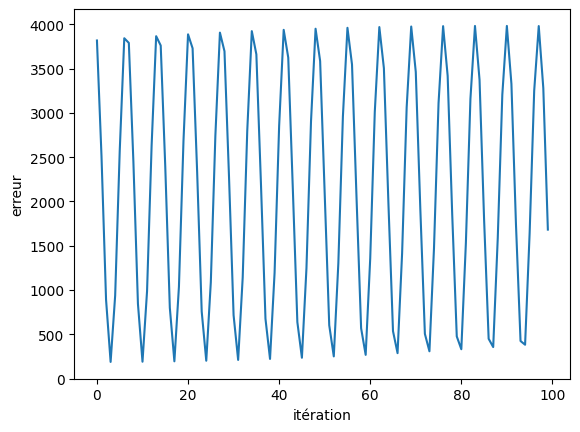

In [12]:
plt.plot(entrainer_sans_remise_a_zero())
plt.xlabel("itération")
plt.ylabel("erreur")
plt.show()

Question : l'erreur baisse-t-elle régulièrement ? Pourquoi ?

*Votre réponse :*

**Corrigé.** Non : l'erreur oscille entre quelques centaines et près de 4000, sans jamais se stabiliser. Chaque itération ajoute son gradient aux précédents : les pas deviennent trop grands, les paramètres dépassent le minimum, repartent en arrière, et ainsi de suite.

## Étape 4 : la boucle corrigée

Complétez les deux TODO : la remise à zéro des gradients, puis la mise à jour de `w` et `b` (un petit pas à l'opposé du gradient, sous `torch.no_grad()`).

In [13]:
def entrainer(n_iter=300, lr=0.1):
    w = torch.zeros(3, requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    erreurs = []
    for _ in range(n_iter):
        loss = loss_fn(model(x, w, b), y)
        if w.grad is not None:
            w.grad.zero_()
            b.grad.zero_()
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad
            b -= lr * b.grad
        erreurs.append(loss.item())
    return w, b, erreurs

w = tensor([-7.3867,  0.9037,  0.8735])  b = tensor([59.7758])  erreur finale : 187.9


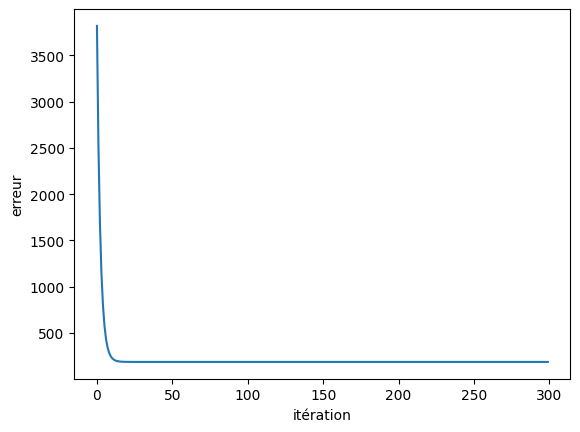

In [14]:
w, b, erreurs = entrainer()
print("w =", w.detach(), " b =", b.detach(), " erreur finale :", round(erreurs[-1], 1))
plt.plot(erreurs)
plt.xlabel("itération")
plt.ylabel("erreur")
plt.show()
assert erreurs[-1] < erreurs[0] / 10, "l'erreur devrait avoir fortement baissé"

**Corrigé.** L'erreur descend en une vingtaine d'itérations, puis se stabilise à 187.9. Le poids de l'âge du conducteur est négatif (-7.3867) : les conducteurs plus âgés ont un meilleur bonus-malus. Ceux de l'âge du véhicule et du nombre de sinistres sont positifs. L'erreur reste élevée : trois informations ne suffisent pas à bien prédire le bonus-malus.

## Étape 5 : vérifier avec la solution exacte (fournie)

Pour un modèle linéaire, il existe une solution exacte, celle des moindres carrés, que calcule `torch.linalg.lstsq`. Vos poids sont-ils les mêmes ?

In [15]:
A = torch.cat([x, torch.ones(len(x), 1)], dim=1)
exacte = torch.linalg.lstsq(A, y.unsqueeze(1)).solution.squeeze()
descente = torch.cat([w.detach(), b.detach()])
print("solution exacte     :", exacte)
print("descente de gradient:", descente)
assert torch.allclose(descente, exacte, atol=1e-2), "les deux solutions devraient coïncider"

solution exacte     : tensor([-7.3867,  0.9037,  0.8735, 59.7758])
descente de gradient: tensor([-7.3867,  0.9037,  0.8735, 59.7758])


**Corrigé.** Les deux solutions coïncident : -7.3867, 0.9037, 0.8735 pour les poids, 59.7761 et 59.7758 pour le biais. La descente de gradient a trouvé la solution exacte.

## Bonus

**B1. Avec un optimiseur.** Refaites l'entraînement avec `torch.optim.SGD`, comme dans la démo 1 : `optimizer.zero_grad()` et `optimizer.step()` remplacent la remise à zéro et la mise à jour. Vérifiez que vous obtenez les mêmes poids.

In [16]:
w_sgd = torch.zeros(3, requires_grad=True)
b_sgd = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD([w_sgd, b_sgd], lr=0.1)
for _ in range(300):
    loss = loss_fn(model(x, w_sgd, b_sgd), y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
print(w_sgd.detach(), b_sgd.detach())
assert torch.allclose(w_sgd, w) and torch.allclose(b_sgd, b)

tensor([-7.3867,  0.9037,  0.8735]) tensor([59.7758])


**Corrigé.** Les mêmes poids : `optimizer.zero_grad()` et `optimizer.step()` font exactement la remise à zéro et la mise à jour écrites à la main.

**B2. Le learning rate.** Relancez `entrainer` avec `lr=1.5`, puis avec `lr=0.001`. Que devient l'erreur ?

In [17]:
for lr in (1.5, 0.001):
    _, _, erreurs_lr = entrainer(lr=lr)
    print(f"lr={lr} : erreur au départ {erreurs_lr[0]:.1f}, à la fin {erreurs_lr[-1]:.1f}")

lr=1.5 : erreur au départ 3817.7, à la fin nan
lr=0.001 : erreur au départ 3817.7, à la fin 1284.1


**Corrigé.** Avec `lr=1.5`, les pas sont trop grands : l'erreur explose jusqu'à `nan`. Avec `lr=0.001`, elle baisse trop lentement : 1284.1 à la fin, loin de l'erreur obtenue à l'étape 4.